In [126]:
%pip install -q kagglehub pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [127]:
import kagglehub
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [128]:
project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

csv_files = list(raw_dir.glob("*.csv"))

if not csv_files:
    download_path = kagglehub.dataset_download("mayuringle8890/electricity")
    for file in Path(download_path).glob("*.csv"):
        shutil.copy(file, raw_dir / file.name)

csv_files = list(raw_dir.glob("*.csv"))
csv_path = csv_files[0]

print("CSV file:", csv_path)

CSV file: c:\Users\Admin\dl-seqforecast\data\raw\Electricity.csv


In [129]:
df_raw = pd.read_csv(csv_path)

print("Shape:", df_raw.shape)
display(df_raw.head())
df_raw.info()

print("\nMissing values by column:")
missing = df_raw.isna().sum()
display(missing)

Shape: (46011, 10)


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
0,2019-01-01 00:00:00,6352,6527,1395,79,1383,1896,1744,0,30
1,2019-01-01 01:00:00,6116,5701,1393,96,1112,1429,1641,0,30
2,2019-01-01 02:00:00,5873,5676,1393,142,1030,1465,1616,0,30
3,2019-01-01 03:00:00,5682,5603,1397,191,972,1455,1558,0,30
4,2019-01-01 04:00:00,5557,5454,1393,159,960,1454,1458,0,30


<class 'pandas.DataFrame'>
RangeIndex: 46011 entries, 0 to 46010
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   DateTime       46011 non-null  str  
 1   Consumption    46011 non-null  int64
 2   Production     46011 non-null  int64
 3   Nuclear        46011 non-null  int64
 4   Wind           46011 non-null  int64
 5   Hydroelectric  46011 non-null  int64
 6   Oil and Gas    46011 non-null  int64
 7   Coal           46011 non-null  int64
 8   Solar          46011 non-null  int64
 9   Biomass        46011 non-null  int64
dtypes: int64(9), str(1)
memory usage: 3.5 MB

Missing values by column:


DateTime         0
Consumption      0
Production       0
Nuclear          0
Wind             0
Hydroelectric    0
Oil and Gas      0
Coal             0
Solar            0
Biomass          0
dtype: int64

| Column Name | Type | Description |
|------------|------|-------------|
| DateTime | Object (Timestamp) | Timestamp representing the exact hour of the record. Can be converted to datetime for time-series indexing. |
| Consumption | Integer | Total electricity consumed during the hour (in MWh). |
| Production | Integer | Total electricity produced during the hour (in MWh). |
| Nuclear | Integer | Electricity generated from nuclear power plants. |
| Wind | Integer | Electricity generated from wind turbines. |
| Hydroelectric | Integer | Electricity generated from hydroelectric power stations. |
| Oil and Gas | Integer | Electricity generated from oil and natural gas sources. |
| Coal | Integer | Electricity generated from coal-based thermal power. |
| Solar | Integer | Electricity generated from solar power plants. |
| Biomass | Integer | Electricity generated from biomass or waste-to-energy plants. |

In [130]:
df_raw["DateTime"] = pd.to_datetime(df_raw["DateTime"], errors="coerce")

print("Invalid DateTime:", df_raw["DateTime"].isna().sum())
print("Start Time:", df_raw["DateTime"].min())
print("End Time:", df_raw["DateTime"].max())

duplicate_rows_before = df_raw.duplicated().sum()
duplicate_timestamps_before = df_raw["DateTime"].duplicated().sum()
print("\nDuplicate rows:", duplicate_rows_before)
print("Duplicate timestamps:", duplicate_timestamps_before)

display(
    df_raw[df_raw["DateTime"].duplicated(keep=False)]
    .sort_values("DateTime")
)

Invalid DateTime: 0
Start Time: 2019-01-01 00:00:00
End Time: 2024-03-31 23:00:00

Duplicate rows: 4
Duplicate timestamps: 9


,DateTime,Consumption,Production,Nuclear,Wind,Hydroelectric,Oil and Gas,Coal,Solar,Biomass
7178,2019-10-27 03:00:00,5186,4478,1373,77,750,696,1532,0,49
7179,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
7180,2019-10-27 03:00:00,5196,4459,1373,74,725,719,1515,0,50
15915,2020-10-25 03:00:00,5181,5356,1417,1120,1155,566,1034,0,65
15916,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
15917,2020-10-25 03:00:00,5220,5412,1418,1188,1098,594,1048,0,65
24820,2021-10-31 03:00:00,5351,5265,1414,108,961,1314,1411,0,56
24821,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
24822,2021-10-31 03:00:00,5341,5258,1415,141,934,1314,1393,0,58
33557,2022-10-30 03:00:00,4475,5266,1385,485,1375,904,1064,0,52


In [131]:
# Remove only completely duplicate rows
df = df_raw.drop_duplicates().copy()
df = df.sort_values("DateTime", kind="stable").reset_index(drop=True)

# Mark timestamps that appear multiple times
duplicate_mask = df["DateTime"].duplicated(keep=False)
ambiguous = np.zeros(len(df), dtype=bool)

for _, group in df[duplicate_mask].groupby("DateTime", sort=False):
    i1, i2 = group.index
    ambiguous[i1] = True   # first time: daylight saving time (DST)
    ambiguous[i2] = False  # second time: standard time

# Romanian local time -> UTC
df["DateTime"] = (
    df["DateTime"]
    .dt.tz_localize(
        "Europe/Bucharest",
        ambiguous=ambiguous,
        nonexistent="shift_forward"
    )
    .dt.tz_convert("UTC")
)

print("Rows before processing:", len(df_raw))
print("Duplicate rows removed:", duplicate_rows_before)
print("Duplicate timestamps before UTC:", duplicate_timestamps_before)
print("\nRows after processing:", len(df))
print("Duplicate rows after processing:", df.duplicated().sum())
print("Duplicate timestamps after UTC:", df["DateTime"].duplicated().sum())
print("DateTime data type:", df["DateTime"].dtype)

Rows before processing: 46011
Duplicate rows removed: 4
Duplicate timestamps before UTC: 9

Rows after processing: 46007
Duplicate rows after processing: 0
Duplicate timestamps after UTC: 0
DateTime data type: datetime64[us, UTC]


In [132]:
time_diff_before = df_raw["DateTime"].sort_values().diff().dropna()
time_diff_after = df["DateTime"].sort_values().diff().dropna()

print("Before UTC:")
display(time_diff_before.value_counts().sort_index())

print("After UTC:")
display(time_diff_after.value_counts().sort_index())

print("Min:", df["DateTime"].min())
print("Max:", df["DateTime"].max())

Before UTC:


DateTime
0 days 00:00:00        9
0 days 01:00:00    45995
0 days 02:00:00        6
Name: count, dtype: int64

After UTC:


DateTime
0 days 01:00:00    46006
Name: count, dtype: int64

Min: 2018-12-31 22:00:00+00:00
Max: 2024-03-31 20:00:00+00:00


Romania uses Daylight Saving Time (DST), which causes time zone shifts between UTC+2 and UTC+3. To avoid issues with duplicate or missing timestamps due to DST and to ensure evenly spaced time series, the data were converted to UTC. After normalization, the dataset consists of 46,007 continuous hourly observations with no duplicate or missing timestamps.

In [133]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Consumption,46007.0,6587.748821,1043.599203,3889.0,5773.0,6552.0,7321.0,9615.0
Production,46007.0,6518.769013,986.752998,3315.0,5814.0,6462.0,7176.0,9886.0
Nuclear,46007.0,1291.168257,236.557773,562.0,1347.0,1383.0,1405.0,1457.0
Wind,46007.0,792.337449,675.823462,-26.0,236.0,592.0,1205.0,2811.0
Hydroelectric,46007.0,1857.125959,692.574677,175.0,1347.0,1747.0,2265.0,4434.0
Oil and Gas,46007.0,1171.915122,434.752299,198.0,858.0,1211.0,1511.0,2141.0
Coal,46007.0,1193.151760,320.457227,279.0,962.0,1172.0,1406.0,2537.0
Solar,46007.0,156.701654,229.507977,0.0,0.0,2.0,280.5,1137.0
Biomass,46007.0,55.851827,14.236068,17.0,45.0,57.0,67.0,89.0


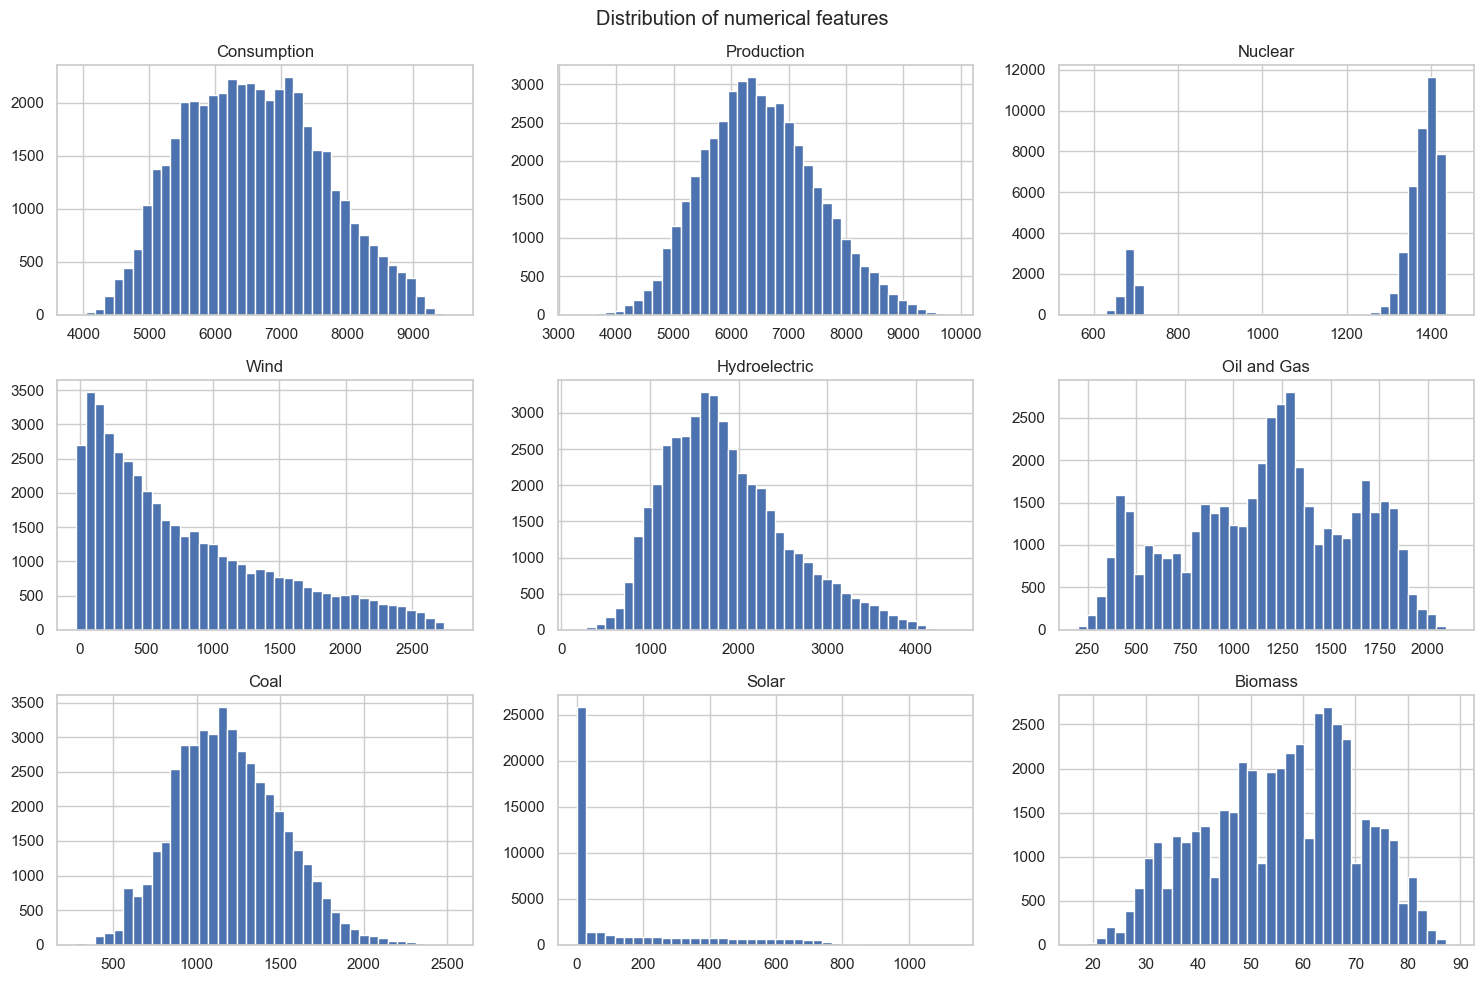

In [134]:
df[numeric_cols].hist(figsize=(15, 10), bins=40)
plt.suptitle("Distribution of numerical features")
plt.tight_layout()
plt.show()

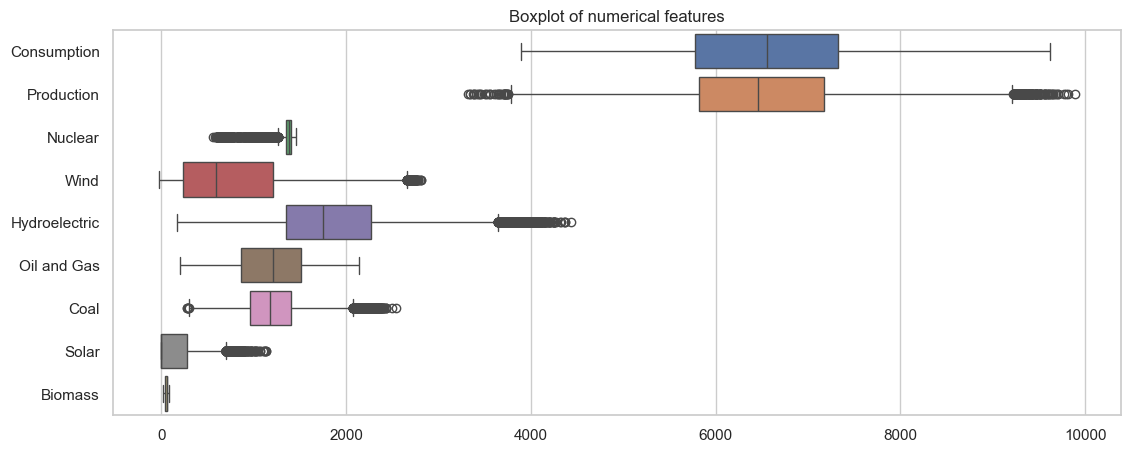

In [135]:
plt.figure(figsize=(13, 5))
sns.boxplot(data=df[numeric_cols], orient="h")
plt.title("Boxplot of numerical features")
plt.show()

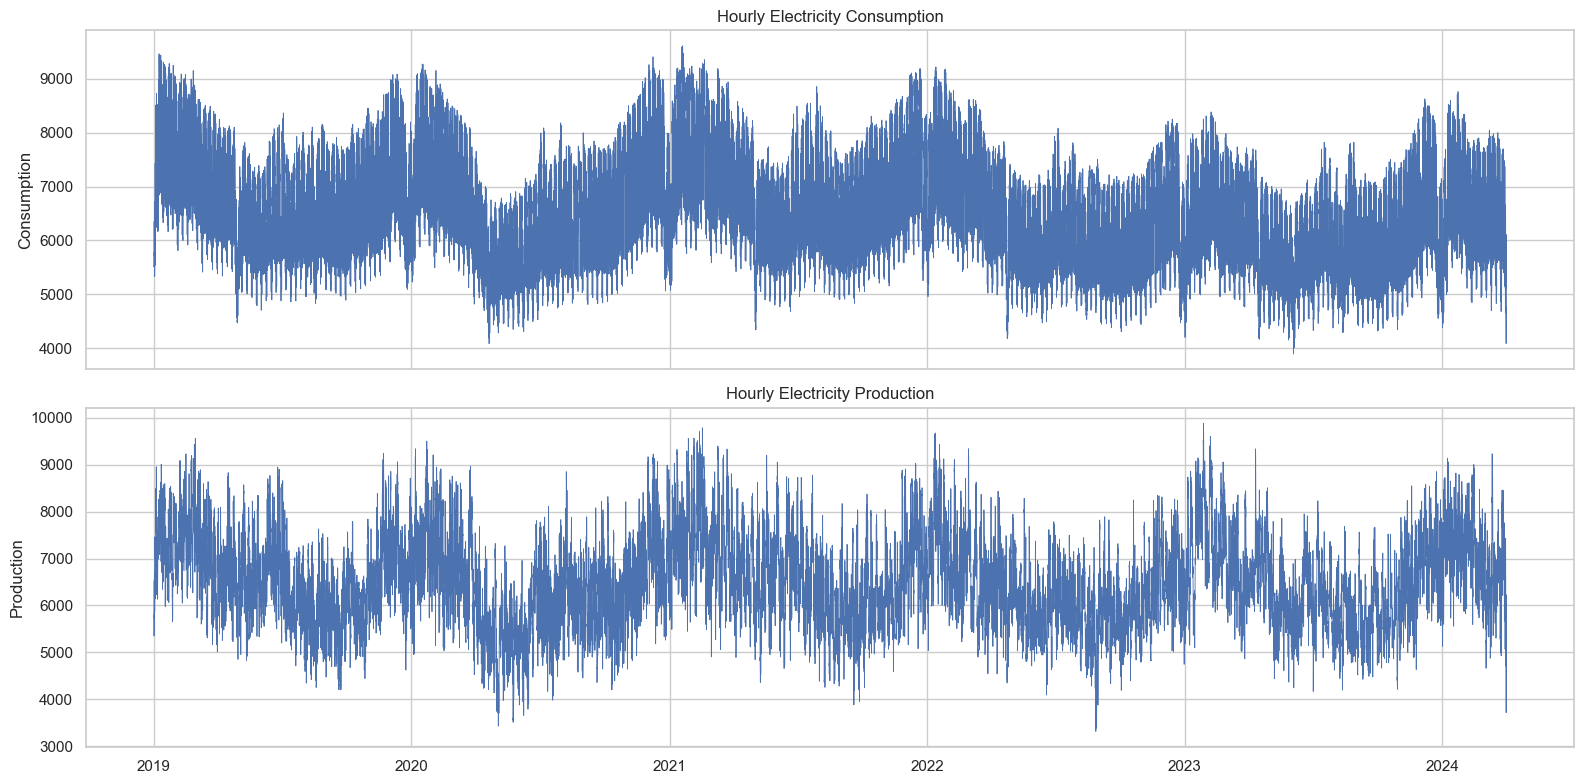

In [136]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(df["DateTime"], df["Consumption"], linewidth=0.6)
axes[0].set_title("Hourly Electricity Consumption")
axes[0].set_ylabel("Consumption")

axes[1].plot(df["DateTime"], df["Production"], linewidth=0.6)
axes[1].set_title("Hourly Electricity Production")
axes[1].set_ylabel("Production")

plt.tight_layout()
plt.show()

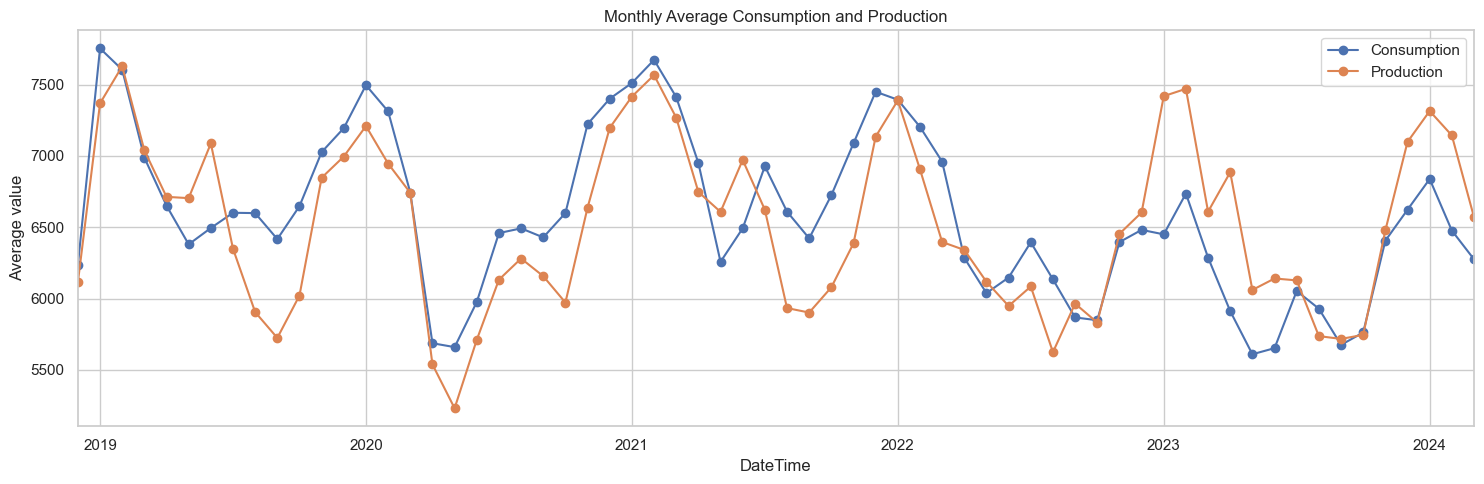

In [137]:
# Monthly averages provide a clearer view of long-term trends. 
monthly = (
    df.set_index("DateTime")[["Consumption", "Production"]]
    .resample("MS")
    .mean()
)

monthly.plot(figsize=(15, 5), marker="o")
plt.title("Monthly Average Consumption and Production")
plt.ylabel("Average value")
plt.xlabel("DateTime")
plt.tight_layout()
plt.show()

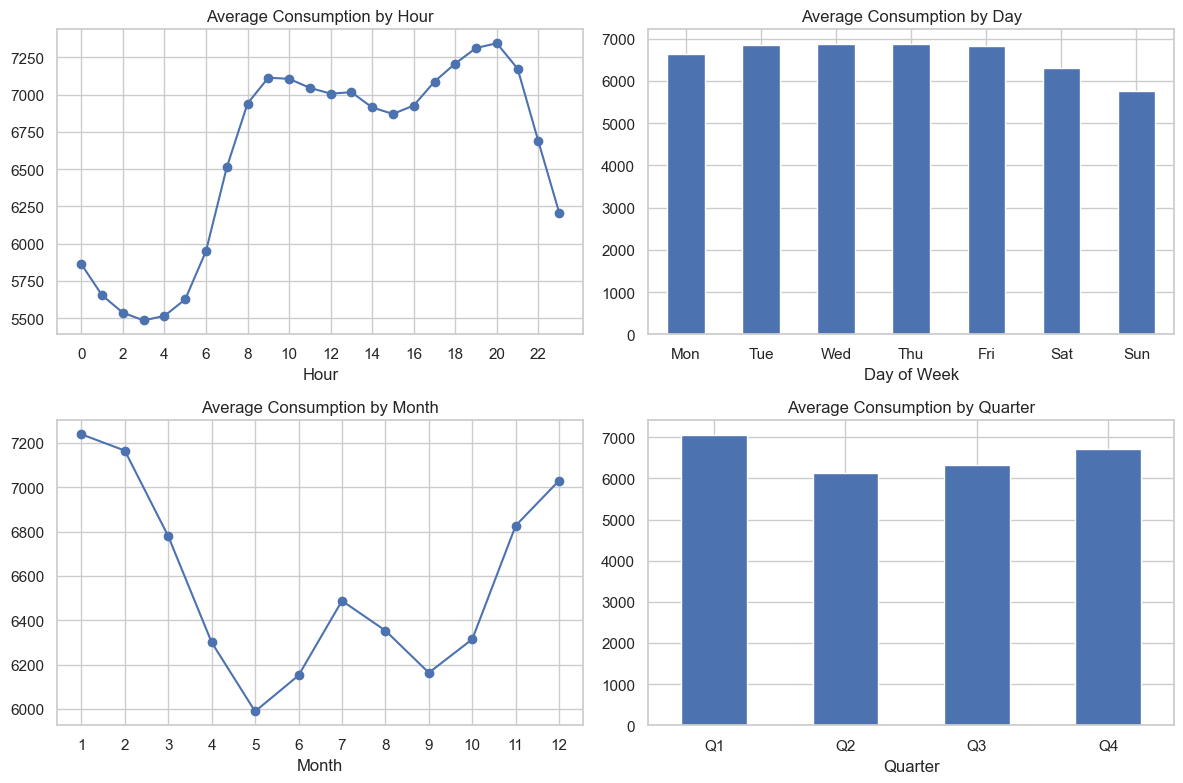

In [138]:
# UTC is used for time order; convert to Romanian time for analyzing daily routines.
df["LocalDateTime"] = df["DateTime"].dt.tz_convert("Europe/Bucharest")
df["Hour"] = df["LocalDateTime"].dt.hour
df["DayOfWeek"] = df["LocalDateTime"].dt.dayofweek
df["Month"] = df["LocalDateTime"].dt.month
df["Quarter"] = df["LocalDateTime"].dt.quarter

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# By the hour
df.groupby("Hour")["Consumption"].mean().plot(
    marker="o", ax=axes[0, 0]
)
axes[0, 0].set_title("Average Consumption by Hour")
axes[0, 0].set_xlabel("Hour")
axes[0, 0].set_xticks(range(0, 24, 2))

# By the day of the week
df.groupby("DayOfWeek")["Consumption"].mean().plot(
    kind="bar", ax=axes[0, 1]
)
axes[0, 1].set_title("Average Consumption by Day")
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)

# By the month
df.groupby("Month")["Consumption"].mean().plot(
    marker="o", ax=axes[1, 0]
)
axes[1, 0].set_title("Average Consumption by Month")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_xticks(range(1, 13))

# By the quarter
df.groupby("Quarter")["Consumption"].mean().plot(
    kind="bar", ax=axes[1, 1]
)
axes[1, 1].set_title("Average Consumption by Quarter")
axes[1, 1].set_xlabel("Quarter")
axes[1, 1].set_xticklabels(["Q1", "Q2", "Q3", "Q4"], rotation=0)

plt.tight_layout()
plt.show()

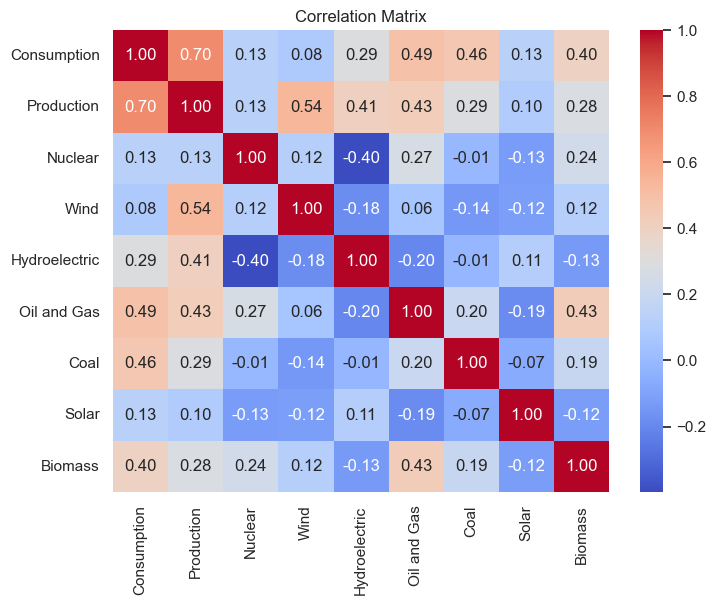

In [139]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

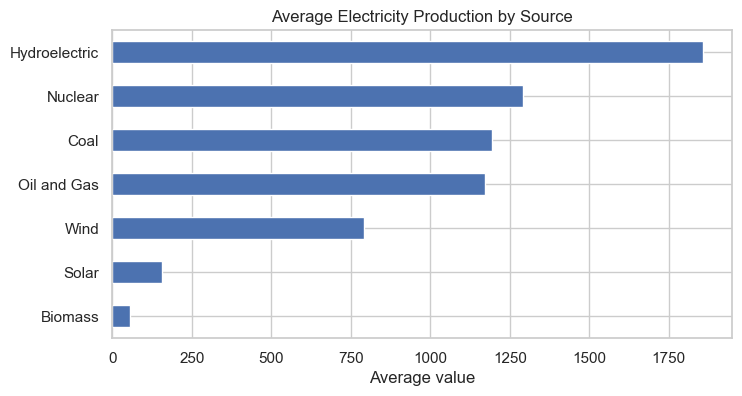

count    46007.000000
mean         0.516987
std         26.632097
min       -694.000000
25%          0.000000
50%          1.000000
75%          2.000000
max        821.000000
Name: Production_Difference, dtype: float64

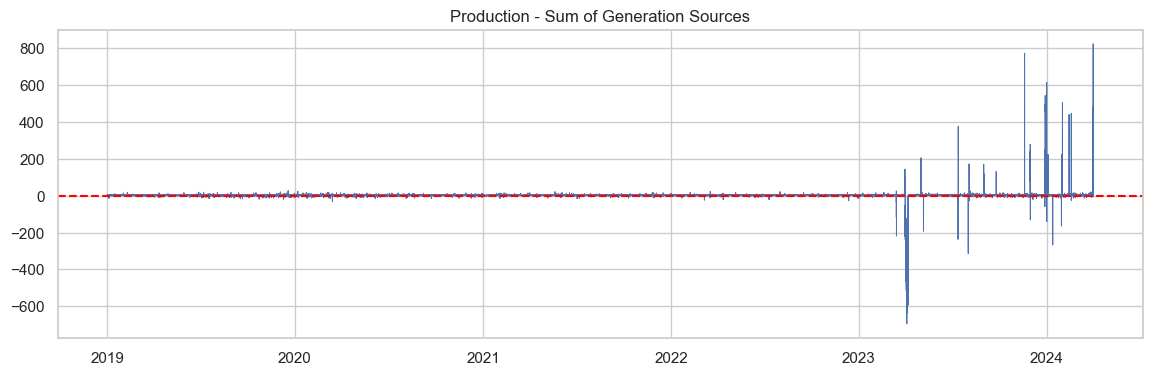

In [140]:
source_cols = [
    "Nuclear", "Wind", "Hydroelectric",
    "Oil and Gas", "Coal", "Solar", "Biomass"
]

source_cols = [col for col in source_cols if col in df.columns]
df[source_cols].mean().sort_values().plot(
    kind="barh", figsize=(8, 4), title="Average Electricity Production by Source"
)
plt.xlabel("Average value")
plt.show()

df["Source_Total"] = df[source_cols].sum(axis=1)
df["Production_Difference"] = df["Production"] - df["Source_Total"]

display(df["Production_Difference"].describe())

plt.figure(figsize=(14, 4))
plt.plot(df["DateTime"], df["Production_Difference"], linewidth=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.title("Production - Sum of Generation Sources")
plt.show()

In [141]:
print("Number of negative values ​​per column:")
display((df[numeric_cols] < 0).sum())

negative_wind = df[df["Wind"] < 0]

print("Number of negative Wind values:", len(negative_wind))
display(negative_wind[
    ["DateTime", "Consumption", "Production", "Wind", "Production_Difference"]
].head(10))

print("Wind Statistics:")
display(negative_wind["Wind"].describe())

Number of negative values ​​per column:


Consumption        0
Production         0
Nuclear            0
Wind             499
Hydroelectric      0
Oil and Gas        0
Coal               0
Solar              0
Biomass            0
dtype: int64

Number of negative Wind values: 499


,DateTime,Consumption,Production,Wind,Production_Difference
10,2019-01-01 08:00:00+00:00,5643,5610,-5,0
11,2019-01-01 09:00:00+00:00,5737,5733,-17,-4
12,2019-01-01 10:00:00+00:00,5776,5816,-10,0
635,2019-01-27 09:00:00+00:00,7197,6346,-4,0
636,2019-01-27 10:00:00+00:00,7116,6246,-6,1
946,2019-02-09 08:00:00+00:00,7946,7999,-6,18
947,2019-02-09 09:00:00+00:00,8039,8114,-19,3
948,2019-02-09 10:00:00+00:00,7898,8062,-22,1
949,2019-02-09 11:00:00+00:00,7770,8067,-16,1
950,2019-02-09 12:00:00+00:00,7498,7795,-6,0


Wind Statistics:


count    499.000000
mean      -9.583166
std        6.442719
min      -26.000000
25%      -15.000000
50%       -8.000000
75%       -4.000000
max       -1.000000
Name: Wind, dtype: float64

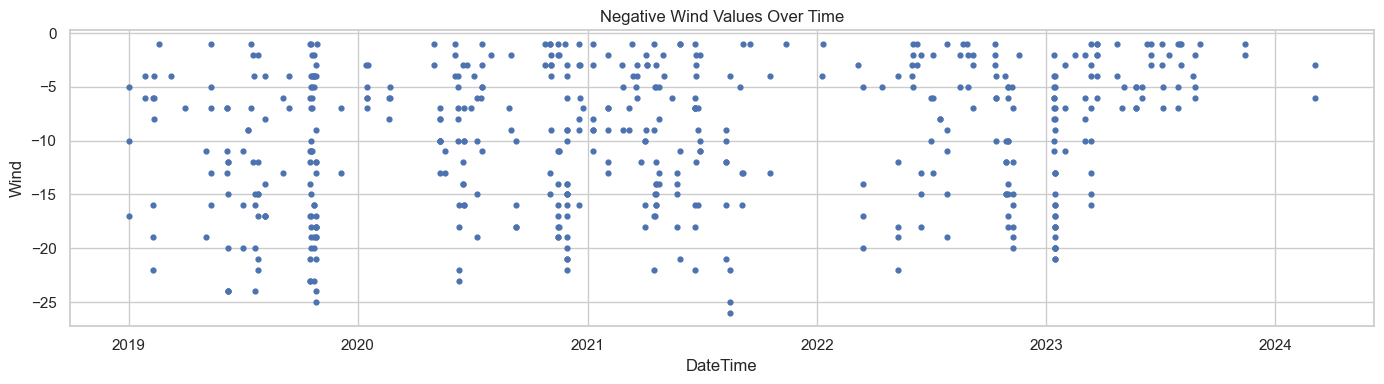

In [142]:
plt.figure(figsize=(14, 4))
plt.scatter(
    negative_wind["DateTime"],
    negative_wind["Wind"],
    s=12
)
plt.title("Negative Wind Values Over Time")
plt.xlabel("DateTime")
plt.ylabel("Wind")
plt.tight_layout()
plt.show()

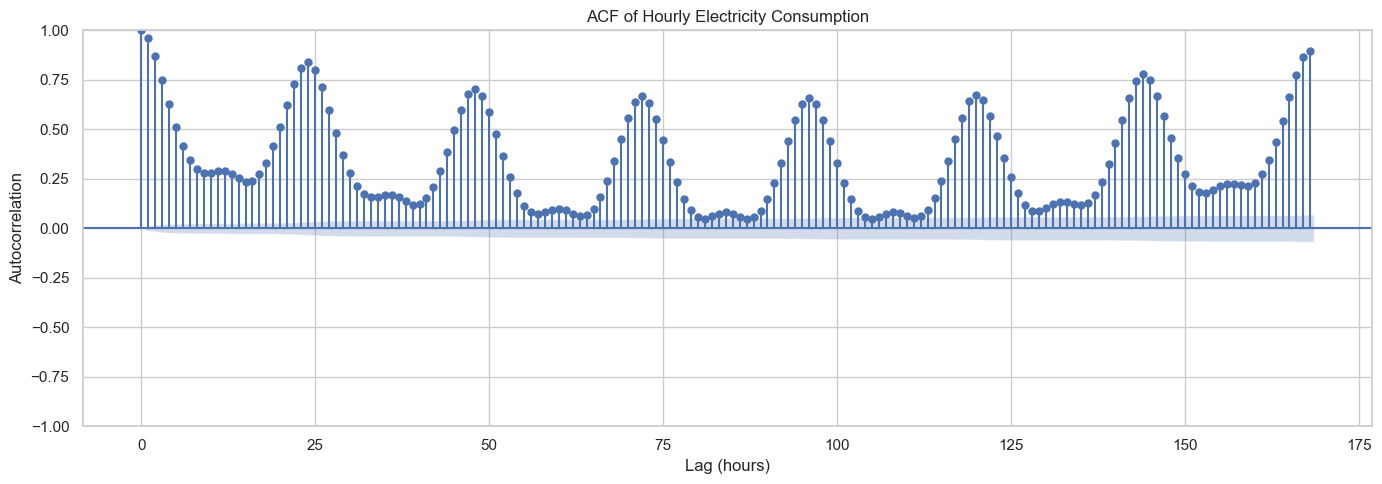

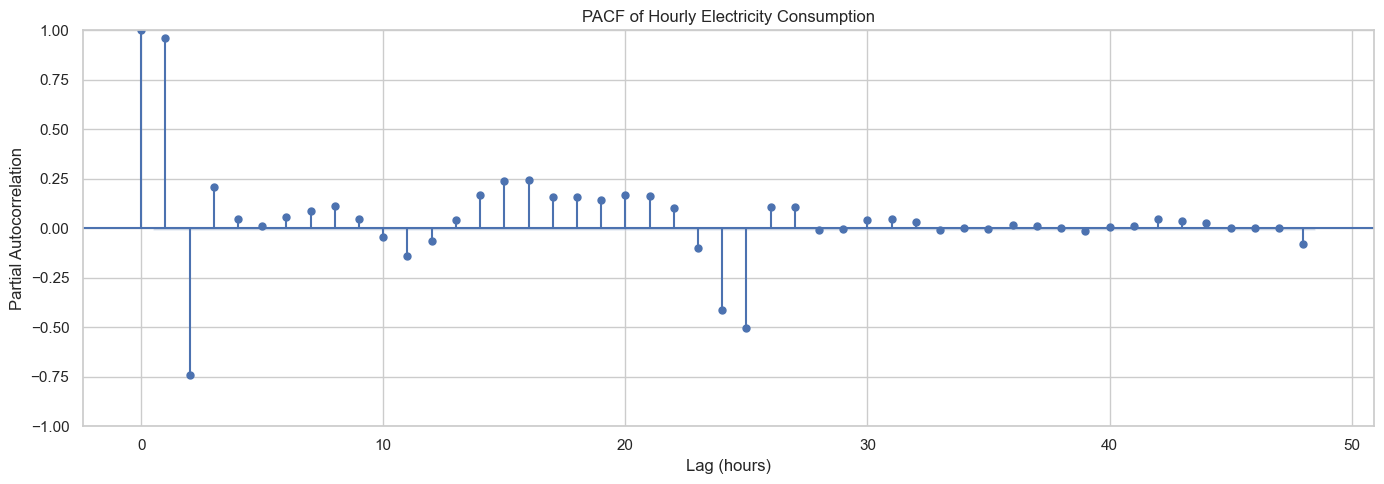

In [143]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Prepare hourly time series
df_eda = df.copy()
df_eda = df_eda.set_index('DateTime').sort_index()
consumption = df_eda['Consumption'].astype(float)

# ACF: autocorrelation at different lags
fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(consumption, lags=168, fft=True, ax=ax)
ax.set_title('ACF of Hourly Electricity Consumption')
ax.set_xlabel('Lag (hours)')
ax.set_ylabel('Autocorrelation')
plt.tight_layout()
plt.show()

# PACF: direct relationship with each lag after accounting for shorter lags
fig, ax = plt.subplots(figsize=(14, 5))
plot_pacf(consumption, lags=48, method='ywm', ax=ax)
ax.set_title('PACF of Hourly Electricity Consumption')
ax.set_xlabel('Lag (hours)')
ax.set_ylabel('Partial Autocorrelation')
plt.tight_layout()
plt.show()

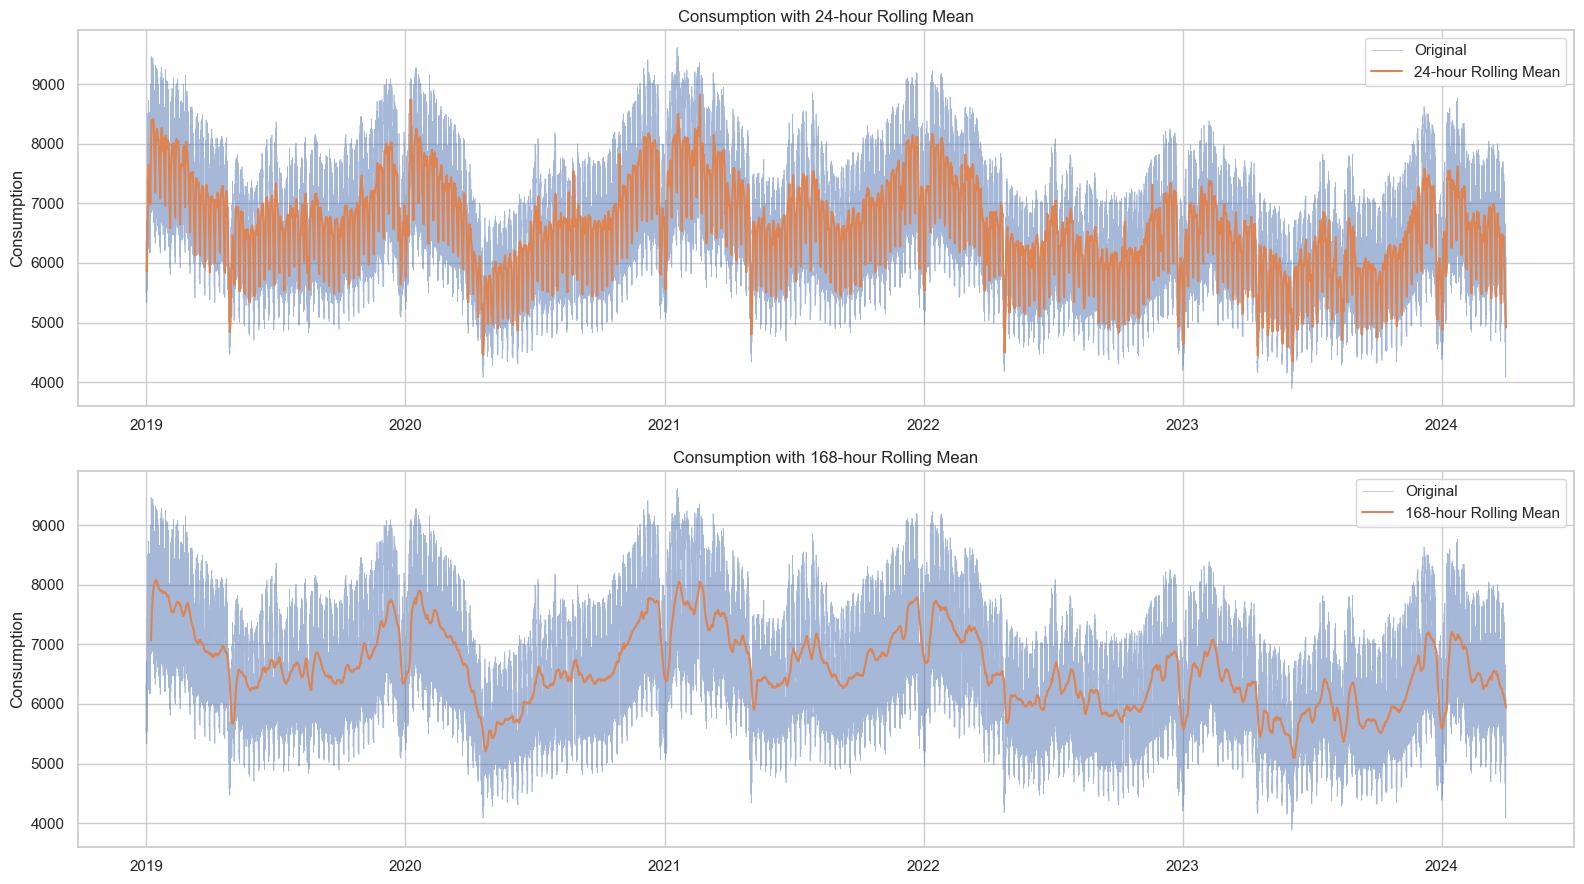

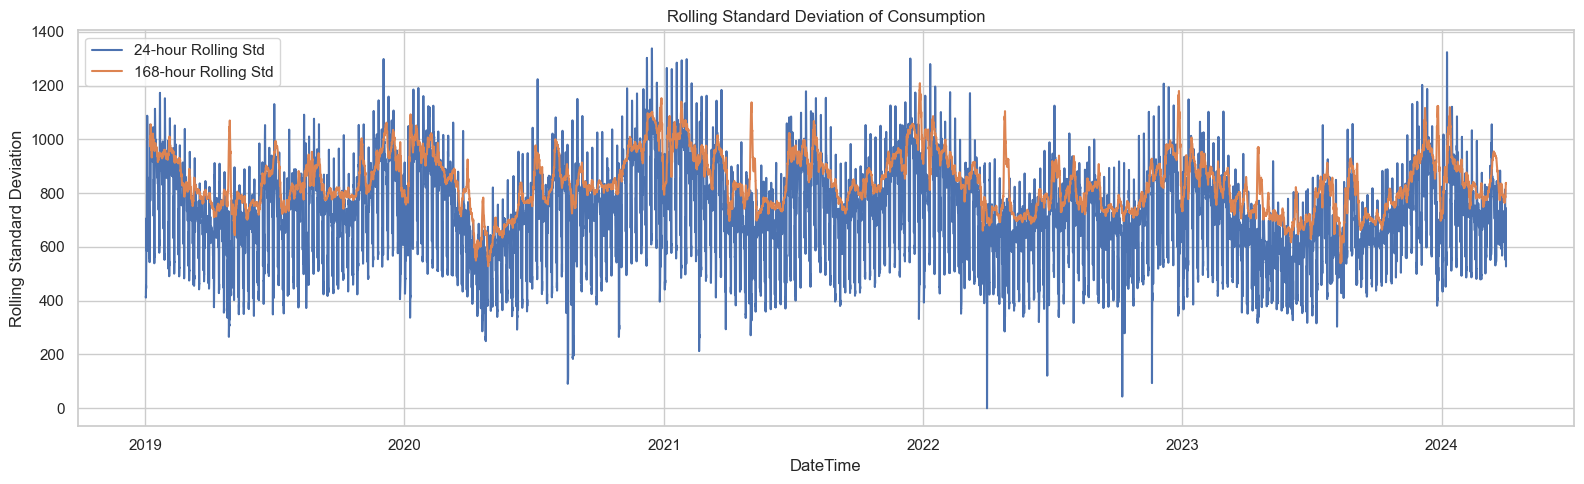

In [144]:
# Calculate rolling statistics
rolling_24h_mean = consumption.rolling(window=24).mean()
rolling_24h_std = consumption.rolling(window=24).std()

rolling_168h_mean = consumption.rolling(window=168).mean()
rolling_168h_std = consumption.rolling(window=168).std()

# Plot rolling mean
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

axes[0].plot(consumption, label='Original', alpha=0.5, linewidth=0.5)
axes[0].plot(rolling_24h_mean, label='24-hour Rolling Mean')
axes[0].set_title('Consumption with 24-hour Rolling Mean')
axes[0].set_ylabel('Consumption')
axes[0].legend()

axes[1].plot(consumption, label='Original', alpha=0.5, linewidth=0.5)
axes[1].plot(rolling_168h_mean, label='168-hour Rolling Mean')
axes[1].set_title('Consumption with 168-hour Rolling Mean')
axes[1].set_ylabel('Consumption')
axes[1].legend()

plt.tight_layout()
plt.show()

# Plot rolling standard deviation
plt.figure(figsize=(16, 5))
plt.plot(rolling_24h_std, label='24-hour Rolling Std')
plt.plot(rolling_168h_std, label='168-hour Rolling Std')

plt.title('Rolling Standard Deviation of Consumption')
plt.xlabel('DateTime')
plt.ylabel('Rolling Standard Deviation')
plt.legend()
plt.tight_layout()
plt.show()

In [145]:
# Save duplicate rows and normalize DateTime to UTC
processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

processed_path = processed_dir / "electricity_utc.csv"

# Do not save extra columns for EDA only
eda_only_cols = [ 
"LocalDateTime", "Hour", "DayOfWeek", "Month", "Quarter", "Production_Difference", "Source_Total"
]
df_to_save = df.drop(columns=eda_only_cols, errors="ignore")
df_to_save.to_csv(processed_path, index=False)

print("Saved:", processed_path)
print("Final shape:", df_to_save.shape)
print("Missing values:", df_to_save.isna().sum().sum())
print("Duplicate timestamps:", df_to_save["DateTime"].duplicated().sum())

Saved: c:\Users\Admin\dl-seqforecast\data\processed\electricity_utc.csv
Final shape: (46007, 10)
Missing values: 0
Duplicate timestamps: 0


##### **Summary**
- The dataset contains 46,007 hourly observations from January 2019 to March 2024, with no missing values or duplicate timestamps after preprocessing.
- Average Consumption and Production are approximately 6,588 MWh and 6,519 MWh per hour, respectively.
- Electricity demand shows clear daily, weekly, and seasonal patterns: peaks around 8 PM, is higher on weekdays (Wed & Thu), and reaches its highest levels in Q1 (January–February).
- Consumption is most strongly correlated with Production (0.695), Oil and Gas (0.489), and Coal (0.462).
- The largest generation sources are hydropower, nuclear, coal, and oil & gas.
- 499 negative Wind values were identified and should be treated as data anomalies.
- Production generally matches the sum of generation sources, with only small average differences.
- ACF/PACF and rolling statistics indicate strong 24-hour and 168-hour seasonality, supporting the use of time-series forecasting models.